# J-lens 101: reading a tiny network

**About 20 minutes · CPU only · no model downloads**

We will teach a tiny network four country–capital pairs, then pause it after its
first hidden layer. Can we read its answer before it reaches the last layer?

You only need the idea that a neural network transforms a list of numbers into
another list. We will introduce everything else as we go.

**This is a teaching model:** three small hidden layers, not a transformer or an
LLM. It memorizes four facts. We implement the averaged-Jacobian idea directly
with PyTorch so the mechanism is visible; this notebook does **not** run Anthropic's
official package or reproduce the paper's experiments.

Dependencies: `torch` and `matplotlib`. If needed, install them in your notebook
environment with `pip install torch matplotlib`. Then choose **Run All**.


## 1. Give the model four facts

The inputs are countries; the possible outputs are four capital-city words.
Each country gets a different four-number input vector. For example, France is
`[1, 0, 0, 0]`. This is called **one-hot encoding**.

These are IDs, not a description of geography. The network must learn the mapping.


In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(7)
torch.set_num_threads(1)
countries = ["France", "Italy", "Japan", "Kenya"]
words = ["Paris", "Rome", "Tokyo", "Nairobi"]
X = torch.eye(4)
y = torch.arange(4)


## 2. Build the tiny model

The model turns 4 input numbers into 8 hidden numbers, transforms those numbers
twice more, and finally produces 4 output scores.

**COUNTRY → HIDDEN 1 → HIDDEN 2 → HIDDEN 3 → WORD SCORES**

`Linear` mixes coordinates using learned weights. `Tanh` bends the result
nonlinearly. The last `Linear` layer translates hidden coordinates into word
scores. In an LLM, this final translation is called the **unembedding**.
We omit biases to keep the formulas short.


In [2]:
model = nn.Sequential(
    nn.Linear(4, 8, bias=False), nn.Tanh(),  # Hidden layer 1
    nn.Linear(8, 8, bias=False), nn.Tanh(),  # Hidden layer 2
    nn.Linear(8, 8, bias=False), nn.Tanh(),  # Hidden layer 3
    nn.Linear(8, 4, bias=False),            # Word scores
)


## 3. Learn the facts

Cross-entropy penalizes the model when the correct word receives too little
probability. The optimizer adjusts the weights. Four facts are enough for this
demonstration; they are **not** enough to evaluate generalization.


In [3]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.03)
for _ in range(300):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X), y)
    loss.backward()
    optimizer.step()

for country, prediction in zip(countries, model(X).argmax(dim=1)):
    print(f"{country:8} → {words[int(prediction)]}")


France   → Paris
Italy    → Rome
Japan    → Tokyo
Kenya    → Nairobi


## 4. Stop after the first hidden layer

We name three pieces of the trained model:

- `early`: country → first hidden vector;
- `remaining`: first hidden vector → final hidden vector;
- `readout`: final hidden vector → word scores.

A hidden vector has eight coordinates, not eight named concepts. The final
readout learned how to interpret the **final** coordinates. There is no reason
it must interpret the earlier coordinates correctly.


In [4]:
early = model[:2]
remaining = model[2:6]
readout = model[6]
H = early(X).detach()

print("France's first hidden vector:")
print(H[0].round(decimals=2))
print("Shape of all four hidden vectors:", tuple(H.shape))


France's first hidden vector:
tensor([-0.3600,  0.2200, -0.5500, -0.7500,  0.6100,  0.7900, -0.4400, -0.0300])
Shape of all four hidden vectors: (4, 8)


## 5. The naive readout: try the final dictionary too early

First, apply the final readout directly to the first hidden layer. This resembles
the simplest **logit lens** idea.

A *logit* is an output score before softmax. The highest score identifies the
top-ranked word. Scores themselves are not probabilities.


In [5]:
raw_scores = readout(H).detach()
for country, prediction in zip(countries, raw_scores.argmax(dim=1)):
    print(f"{country:8} → {words[int(prediction)]}")


France   → Tokyo
Italy    → Rome
Japan    → Nairobi
Kenya    → Nairobi


## 6. Ask how earlier coordinates affect later coordinates

Let $F$ be `remaining`. A **Jacobian** is a table of derivatives:

$$J_{ij}(h)=\frac{\partial F_i(h)}{\partial h_j}.$$

Entry $(i,j)$ asks: if we nudge early coordinate $j$, how much does final
coordinate $i$ change? Here the table is only $8\times8$.

For a small nudge $\Delta h$,

$$F(h+\Delta h)\approx F(h)+J(h)\Delta h.$$

PyTorch can calculate this table. We average it over our four inputs to obtain
one fixed transport matrix. The real J-lens uses a richer averaging procedure
over contexts and token positions; this tiny network has just one position.


In [6]:
jacobians = [torch.autograd.functional.jacobian(remaining, h) for h in H]
J = torch.stack(jacobians).mean(dim=0)
print("Average Jacobian shape:", tuple(J.shape))


Average Jacobian shape: (8, 8)


## 7. Transport, then read

Instead of reading $h$ directly, read $Jh$:

$$\text{naive scores}=Uh,\qquad
\text{lens scores}=U\bar J h.$$

$U$ is the learned readout matrix. We use `H @ J.T` because our examples are
stored as rows rather than columns.

**An important limit:** the derivative formula above concerns small changes.
Multiplying an entire activation by the average Jacobian is a readout heuristic;
it is not an exact reconstruction of $F(h)$. It can fail. We have not fitted
an intercept or evaluated a full nonlinear continuation here.


In [7]:
lens_scores = readout(H @ J.T).detach()
actual_scores = model(X).detach()

print(f"{'Country':8} {'Naive':10} {'J-lens':10} {'Full model':10}")
for i, country in enumerate(countries):
    predictions = [words[int(scores[i].argmax())]
                   for scores in (raw_scores, lens_scores, actual_scores)]
    print(f"{country:8} {predictions[0]:10} {predictions[1]:10} {predictions[2]:10}")


Country  Naive      J-lens     Full model
France   Tokyo      Paris      Paris     
Italy    Rome       Rome       Rome      
Japan    Nairobi    Tokyo      Tokyo     
Kenya    Nairobi    Nairobi    Nairobi   


## 8. Look at one example

With the supplied seed, the transported readout recovers the four learned
answers, while the naive readout misses some. That is an illustration of the
mechanism, **not evidence that J-lens always improves decoding**.

Change `country` below and rerun this cell. Compare which word ranks first.
The score magnitudes across the two methods need not be calibrated alike.


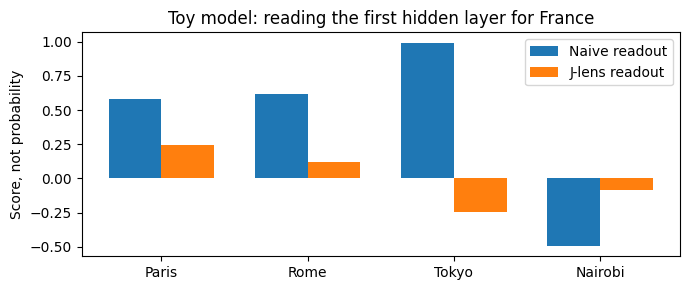

In [8]:
country = "France"
i = countries.index(country)
p = torch.arange(len(words)).numpy()
plt.figure(figsize=(7, 3))
plt.bar(p - 0.18, raw_scores[i].numpy(), width=0.36, label="Naive readout")
plt.bar(p + 0.18, lens_scores[i].numpy(), width=0.36, label="J-lens readout")
plt.xticks(p, words)
plt.ylabel("Score, not probability")
plt.title(f"Toy model: reading the first hidden layer for {country}")
plt.legend()
plt.tight_layout()
plt.show()


## What did we learn?

1. A hidden vector is not directly a list of word meanings.
2. The final readout understands the final layer's coordinates.
3. A Jacobian describes how changes in earlier coordinates affect later ones.
4. An averaged Jacobian can give us a useful way to read earlier activations.
5. A readable result is not automatically a correctness score or a causal explanation.

**Try three small experiments:**

- Change the random seed and run all cells. Does the same improvement persist?
- Train for only 10 steps. Can a lens compensate for a model that has not learned the facts?
- Inspect the second hidden layer: change `early` to `model[:4]` and `remaining`
  to `model[4:6]`, then rerun from Section 4. What changes?

## How this connects to our project

Our real experiment reads Qwen's token-prefix activations through the official
J-lens implementation. It includes token-position averaging and normalization
that this teaching example omits. We then test whether those features predict
eventual mathematical success. The capital-city demonstration establishes none
of those empirical results—it only makes the readout mechanism concrete.

There is no PPO, LSTD, critic fitting, vocabulary compression or cluster setup
in this notebook. Those are separate questions to study after the lens itself.

**Next:** [official J-lens walkthrough](https://github.com/anthropics/jacobian-lens/blob/main/walkthrough.ipynb),
[paper](https://transformer-circuits.pub/2026/workspace/index.html),
and [Article 3](03-reading-a-model-through-jlens.md).
